# 03 — Exploratory Data Analysis (EDA)
**Project:** Telco Customer Churn Predictor  
**Author:** Ibtissam Bukhari  
**Goal:** Understand the data deeply, find patterns,
and discover what drives customer churn.

---

## Questions We Answer In This Notebook
1. How many customers churned vs stayed?
2. Do demographic factors affect churn?
3. Do services affect churn?
4. Does contract type affect churn?
5. Do charges and tenure affect churn?
6. Which features are most correlated?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/processed/telco_cleaned.csv')

# visual style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

print("Data loaded")
print(f"Shape: {df.shape}")

Data loaded
Shape: (7010, 20)


## Step 1 — Churn Distribution
How balanced is our dataset?
This tells us if we have a class imbalance problem.

C:\Users\Ibtissam Bukhari\AppData\Local\Temp\ipykernel_3212\1212821787.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Churn', data=df, palette=['#2ecc71', '#e74c3c'])


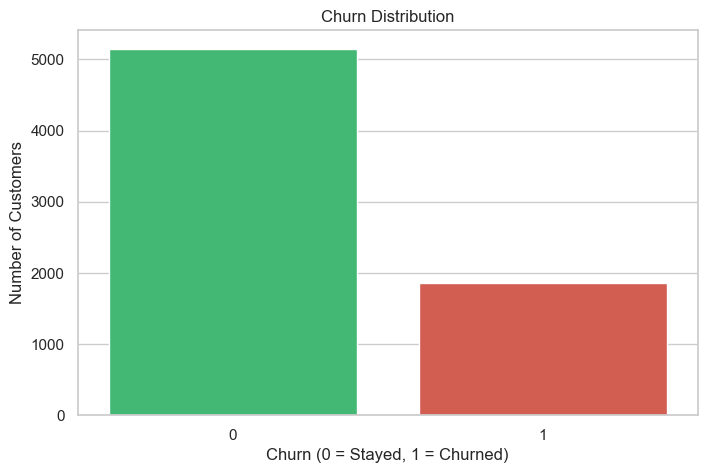

In [2]:
ax = sns.countplot(x='Churn', data=df, palette=['#2ecc71', '#e74c3c'])
ax.set_title('Churn Distribution')
ax.set_xlabel('Churn (0 = Stayed, 1 = Churned)')
ax.set_ylabel('Number of Customers')

plt.savefig('../outputs/figures/01_churn_distribution.png', dpi=150)
plt.show()

## Step 2 — Contract Type vs Churn
Contract type is one of the strongest churn drivers.
Do customers on month-to-month contracts churn more?

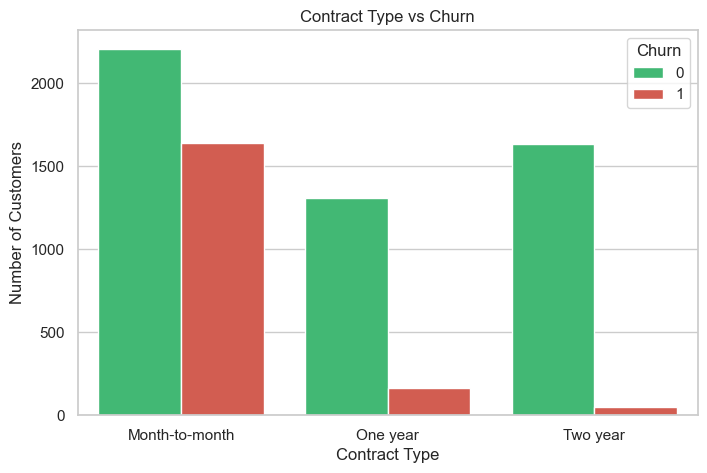

In [3]:
ax = sns.countplot(x='Contract', hue='Churn', data=df,
                   palette=['#2ecc71', '#e74c3c'])
ax.set_title('Contract Type vs Churn')
ax.set_xlabel('Contract Type')
ax.set_ylabel('Number of Customers')

plt.savefig('../outputs/figures/02_contract_vs_churn.png', dpi=150)
plt.show()

## Step 3 — Tenure vs Churn
Does how long a customer has been with the company affect churn?
New customers vs long term customers — who churns more?

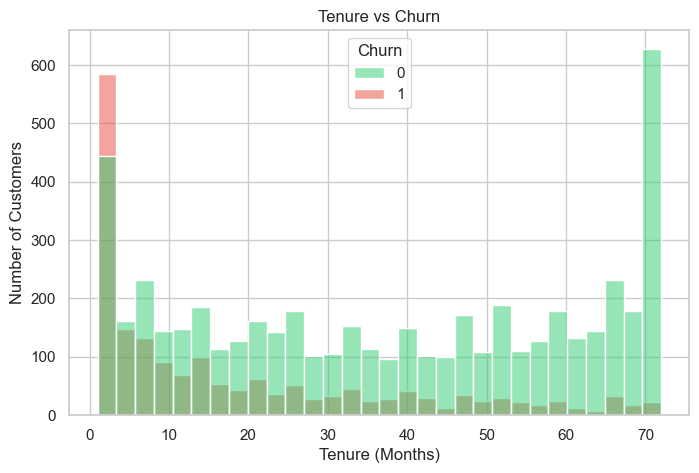

In [4]:
sns.histplot(data=df, x='tenure', hue='Churn',
             bins=30, palette=['#2ecc71', '#e74c3c'])

plt.title('Tenure vs Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.savefig('../outputs/figures/03_tenure_vs_churn.png', dpi=150)
plt.show()

## Step 4 — Monthly Charges vs Churn
Do customers who pay more churn more?
Are expensive plans driving customers away?

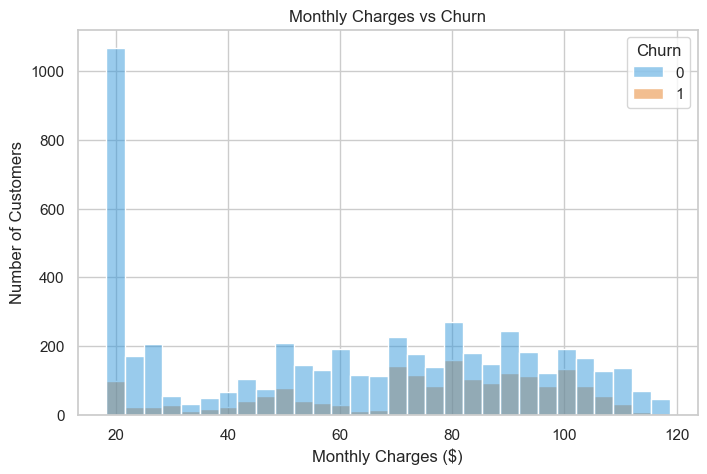

In [6]:
sns.histplot(data=df, x='MonthlyCharges', hue='Churn',
             bins=30, palette=['#3498db', '#e67e22'])

plt.title('Monthly Charges vs Churn')
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Number of Customers')

plt.savefig('../outputs/figures/04_monthlycharges_vs_churn.png', dpi=150)
plt.show()

## Step 5 — Correlation Heatmap
Which numerical features are related to each other?
High correlation between two features means they carry
similar information — useful for feature selection later.

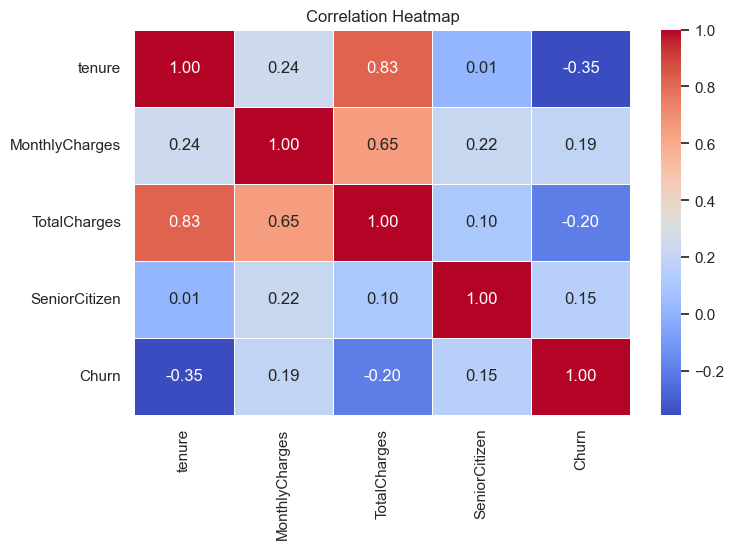

In [7]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']

corr_matrix = df[numerical_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=0.5)

plt.title('Correlation Heatmap')

plt.savefig('../outputs/figures/05_correlation_heatmap.png', dpi=150)
plt.show()

## Step 6 — Internet Service vs Churn
Does the type of internet service affect churn?
Fiber optic is expensive — do those customers churn more?

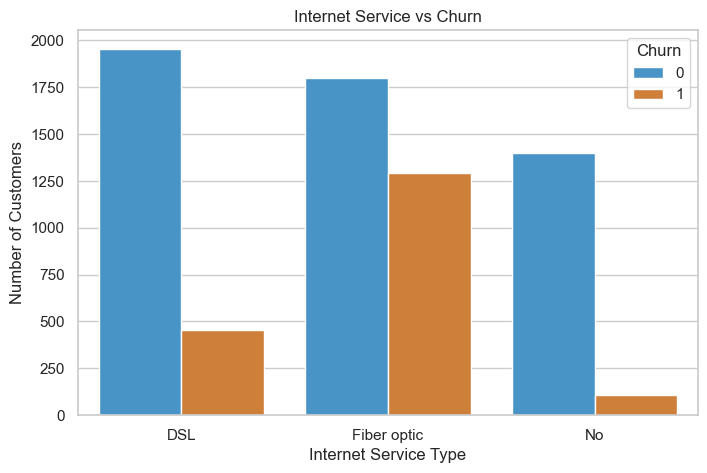

In [9]:
ax = sns.countplot(x='InternetService', hue='Churn', data=df,
                   palette=['#3498db', '#e67e22'])

ax.set_title('Internet Service vs Churn')
ax.set_xlabel('Internet Service Type')
ax.set_ylabel('Number of Customers')

plt.savefig('../outputs/figures/06_internet_vs_churn.png', dpi=150)
plt.show()

## Step 7 — Senior Citizen vs Churn
Do senior citizens churn more than younger customers?

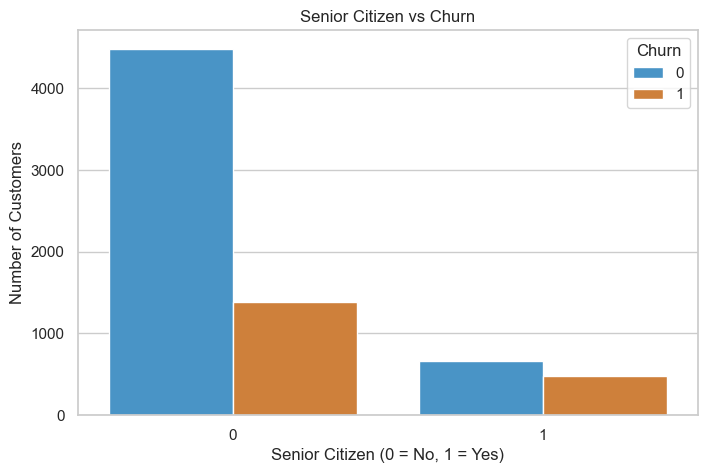

In [10]:
ax = sns.countplot(x='SeniorCitizen', hue='Churn', data=df,
                   palette=['#3498db', '#e67e22'])

ax.set_title('Senior Citizen vs Churn')
ax.set_xlabel('Senior Citizen (0 = No, 1 = Yes)')
ax.set_ylabel('Number of Customers')

plt.savefig('../outputs/figures/07_senior_vs_churn.png', dpi=150)
plt.show()

## EDA Summary — Key Business Insights

1. **Contract Type** → month-to-month customers churn the most.
   Longer contracts = lower churn.

2. **Tenure** → new customers (0-10 months) churn the most.
   Early retention is critical.

3. **Monthly Charges** → customers paying $60+ churn more.
   High value customers need special retention offers.

4. **Internet Service** → fiber optic customers churn the most
   despite paying the most.

5. **Senior Citizens** → churn at higher rate relative to their count.
   Need special programs and support.

### Next → 04_feature_engineering.ipynb